# Module 1 · Partie 1 : Exploration et contrôle des données (*Data check*)

---

### Objectifs d'apprentissage
1. Reconnaître les **types de données** (quantitatives discrètes/continues, qualitatives binaires/nominales/ordinales) et leur équivalent dans R.
2. Appliquer la démarche de **data cleaning** du cours : *origin*, *data distribution*, *data validation*.
3. Calculer et interpréter les **paramètres de position** et de **dispersion**, à la main et avec R (`summary`, `descr`…).
4. Lire un **histogramme** et un **boxplot**, reconnaître une distribution symétrique ou asymétrique.
5. Décrire une variable **qualitative** (effectifs, fréquences, cumuls) et construire un **tableau de contingence**.
6. Détecter et traiter les **valeurs anormales** et **manquantes**.
7. Comprendre la **colinéarité** et la **mise à l'échelle** (*autoscaling*, *min-max*).
8. Utiliser une **transformation** (log10, racine carrée) pour se rapprocher de la normalité.

### Prérequis
Notebook `00` (rappels R, structure de `lactoferrin.csv`).

### Sommaire
- 1.1 Types de données
- 1.2 Connaître ses données : *origin*, *distribution*, *validation*
- 1.3 Paramètres de position
- 1.4 Paramètres de dispersion
- 1.5 Tout en une fois : `summary()` et `summarytools::descr()`
- 1.6 Graphiques : histogramme, formes de distribution, boxplot
- 1.7 La loi normale et la règle des 3σ
- 1.8 Variables qualitatives et tableau de contingence
- 1.9 Valeurs anormales et manquantes
- 1.10 Validation des données : comparaison avec la littérature
- 1.11 Données spectrales : beaucoup de variables
- 1.12 Colinéarité
- 1.13 Mise à l'échelle (*scaling*)
- 1.14 Transformations vers la normalité
- Récapitulatif

In [1]:
suppressPackageStartupMessages({
  library(summarytools); library(pander); library(knitr); library(corrplot)
})
options(repr.plot.width = 10, repr.plot.height = 6)

# Lecture des données (dans RStudio : setwd(...) puis read.table("lactoferrin.csv", sep=";"))
lactoferrin <- read.table(file = "../lactoferrin.csv", sep = ";")
dim(lactoferrin)

[1]  178 1062

## 1.1 Types de données

Il existe **deux grandes familles** de données :

```
                         Variable (attribut que l'on donne aux enregistrements)
                       ┌────────────────────┴────────────────────┐
                  Qualitative                               Quantitative
              ┌───────┴────────┐                       ┌──────────┴──────────┐
          Nominale          Ordinale                Discrète             Continue
     (noms de parcelles)  (degré d'infestation)    (comptage)            (mesure)
```

- **Quantitatives** :
  - **discrètes** (comptages) : valeurs entières de 0 à l'infini, ex. nombre d'arbres d'une parcelle ;
  - **continues** (mesures) : valeurs entre −∞ et +∞. Le caractère « discontinu » d'une mesure ne vient que de la **précision** de l'appareil (poids d'un porc au kg près → entiers ; avec une balance plus précise → réels).
- **Qualitatives** (attributs, catégories, modalités) :
  - **binaires** : 2 possibilités (présence/absence) ;
  - **ordinales** : modalités **ordonnées** (intensité d'une attaque de pucerons : nulle, modérée, forte, très forte) ;
  - **nominales** : modalités **non ordonnables** (races bovines, substrats géologiques, types phytosociologiques, couleurs…).

> **Attention** : une variable qualitative peut être **codée numériquement** (absence = 0, présence = 1 ; blanc = 1, rouge = 2…). Elle **ne devient pas** pour autant une variable discrète, sauf si les modalités sont ordonnées. Calculer la « moyenne des couleurs » n'a aucun sens !

Le **choix de la méthode de ML** dépend du type de la variable à expliquer **et** du type des variables explicatives.

### Les types dans R

| Type statistique | Type R | Création |
|---|---|---|
| Quantitative continue | `numeric` (double) | `c(2.5, 3.1)` |
| Quantitative discrète | `integer` | `c(2L, 5L)` ou `as.integer()` |
| Qualitative nominale / binaire | `factor` | `factor(c("Holstein", "Jersey"))` |
| Qualitative ordinale | `ordered` (facteur ordonné) | `factor(x, levels = ..., ordered = TRUE)` |

In [2]:
race <- factor(c("Holstein", "Jersey", "Holstein", "Blanc-Bleu"))
race
levels(race)        # modalités
infest <- factor(c("modérée", "nulle", "très forte", "forte"),
                 levels = c("nulle", "modérée", "forte", "très forte"), ordered = TRUE)
infest
infest > "modérée"  # la comparaison n'a de sens que pour un facteur ordonné
class(lactoferrin$V1); class(lactoferrin$V1062)

[1] Holstein   Jersey     Holstein   Blanc-Bleu
Levels: Blanc-Bleu Holstein Jersey

[1] "Blanc-Bleu" "Holstein"   "Jersey"

[1] modérée    nulle      très forte forte     
Levels: nulle < modérée < forte < très forte

[1] FALSE FALSE  TRUE  TRUE

[1] "integer"

[1] "numeric"

### Exercice 1.1 : quel type ?
Donne le type de chaque variable et le type R adapté : (a) teneur en lactoferrine (mg/L) ; (b) numéro de lactation (1, 2, 3…) ; (c) statut mammite (oui/non) ; (d) note d'état corporel de 1 à 5 ; (e) identifiant `V1` de l'échantillon.

In [3]:
# À toi de jouer ! (réponds en commentaire, ou crée des exemples de vecteurs)

<details>
<summary><b>Voir la solution</b></summary>

- (a) quantitative **continue** → `numeric`.
- (b) quantitative **discrète** (comptage) → `integer` ; on pourrait aussi la traiter en ordinale (primipare/multipare).
- (c) qualitative **binaire** → `factor` (2 niveaux) ou codage 0/1.
- (d) qualitative **ordinale** → `ordered`.
- (e) **identifiant** : codé en entier, mais c'est une étiquette (nominale) : il ne faut jamais l'utiliser comme variable explicative. C'est pourquoi on retire toujours la colonne 1 (`lactoferrin[, -1]`, `lactoferrin[, 2:1062]`).

</details>

## 1.2 Connaître ses données (*Data cleaning — knowing the data*)

Avant toute modélisation, le cours insiste sur trois questions :

| Étape | Questions |
|---|---|
| **Origin** | Comment les données ont-elles été produites ? Répétabilité, reproductibilité, une ou plusieurs sources ? |
| **Data distribution** | Graphiques et statistiques descriptives |
| **Data validation** | Comparaison avec la littérature, étude de la distribution : les valeurs sont-elles **attendues** ? |

### Origin : la variable à expliquer (lactoferrine)
- **Méthode : ELISA**
  - avantage : beaucoup d'échantillons analysés simultanément ;
  - inconvénient : méthode plus ou moins précise ;
  - **répétabilité : ±10 %** (même labo, même opérateur) ; **reproductibilité : ±20 %** (labos/opérateurs différents) ;
  - sources d'erreur : plusieurs dilutions.
- **Laboratoires : 2 ; techniciens : 2** → une variabilité « technique » s'ajoute à la variabilité biologique.

### Origin : les variables explicatives (spectres)
- **Méthode : spectrométrie moyen infrarouge** (FT-MIR)
  - avantage : beaucoup d'échantillons analysés ;
  - inconvénient : **certaines régions sont non informatives** (bruitées) ;
  - répétabilité et reproductibilité **dépendent des régions** spectrales.
- **Laboratoire : 1 ; technicien : 1.**

> **Attention** : la slide indique « N = 173 spectral records » alors que le fichier fourni contient **178** enregistrements (vérifié ci-dessous). On travaille évidemment avec le fichier.

> **Complément** : une reproductibilité de ±20 % signifie qu'un même lait dosé à 100 mg/L par un labo peut l'être à 80 ou 120 mg/L par l'autre. **Aucun modèle ne pourra prédire plus précisément que la référence elle-même** : c'est une borne naturelle à garder en tête quand on jugera les R² et RMSE.

In [4]:
nrow(lactoferrin)   # 178 enregistrements dans le fichier

[1] 178

## 1.3 Paramètres de position

On prépare la variable comme dans la résolution : un data.frame d'une colonne nommée `lactoferrin`.

In [5]:
y <- data.frame(lactoferrin[, 1062])   # on utilise un data.frame pour pouvoir nommer la colonne
names(y) <- c("lactoferrin")
x_lf <- y$lactoferrin                   # vecteur numérique, plus pratique pour les calculs à la main
n <- length(x_lf); n

[1] 178

### Moyenne arithmétique
$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$$
Même unité que les observations. **Inconvénient : sensible aux valeurs extrêmes → peu robuste.**

### Médiane
Valeur telle que la moitié des observations lui sont inférieures ou égales, l'autre moitié supérieures ou égales. Avec les observations **triées** $x_{[1]} \le \dots \le x_{[n]}$ :
$$\tilde{x} = x_{\left[\frac{n+1}{2}\right]} \;\; (n \text{ impair}) \qquad\text{ou}\qquad \tilde{x} = \frac{x_{\left[\frac{n}{2}\right]} + x_{\left[\frac{n}{2}+1\right]}}{2} \;\; (n \text{ pair})$$
La médiane est **robuste**.

### Quartiles
$q_1$ (25 % des observations ≤ $q_1$), $q_2$ = médiane, $q_3$ (75 % ≤ $q_3$). Ils découpent l'échelle en 4 zones contenant chacune un quart des observations.

### Mode
Valeur(s) de **fréquence maximale**. Distribution **unimodale** (un mode) ou **plurimodale**. Son calcul n'a d'intérêt que si n est assez grand (sinon fréquences trop faibles/irrégulières).

### Minimum et maximum
$x_{[1]}$ et $x_{[n]}$.

In [6]:
# Moyenne : à la main puis avec mean()
sum(x_lf) / n
mean(x_lf)

# Médiane : à la main (n = 178 est pair) puis avec median()
xs <- sort(x_lf)
(xs[n/2] + xs[n/2 + 1]) / 2
median(x_lf)

min(x_lf); max(x_lf)

[1] 206.7459

[1] 206.7459

[1] 90.46833

[1] 90.46833

[1] 7.69375

[1] 2038.267

In [7]:
# Quartiles
quantile(x_lf)                       # 0 %, 25 %, 50 %, 75 %, 100 %
quantile(x_lf, probs = c(0.25, 0.75))
quantile(x_lf, 0.9)                  # n'importe quel quantile (ici le 9e décile)

0%        25%        50%        75%       100% 
   7.69375   44.85017   90.46833  222.85325 2038.26700

25%       75% 
 44.85017 222.85325

90% 
585.0526

> **Fonction R** : `quantile(x, probs = seq(0, 1, 0.25), type = 7)`
> - `probs` : vecteur de probabilités (0.25 = 1ᵉʳ quartile, 0.1 = 1ᵉʳ décile…) ;
> - `type` : il existe **9 définitions** de quantile (interpolations différentes) ; R utilise `type = 7` par défaut, `summarytools::descr()` utilise `type = 2`. Les valeurs diffèrent légèrement (44.85 vs 44.54 pour q1 ici) : ce n'est pas une erreur !

In [8]:
quantile(x_lf, c(0.25, 0.75), type = 7)   # celui de summary()
quantile(x_lf, c(0.25, 0.75), type = 2)   # celui de descr() : 44.54 et 223.36 comme dans la résolution

25%       75% 
 44.85017 222.85325

25%    75% 
 44.54 223.36

### Le mode : pas de fonction toute faite dans R
- Variable **discrète/qualitative** : la modalité la plus fréquente → `names(which.max(table(x)))`.
- Variable **continue** : toutes les valeurs sont (quasi) uniques ; on prend le **centre de la classe** la plus fréquente de l'histogramme (classe modale).

In [9]:
# Variable discrète : exemple
lactation <- c(1, 2, 2, 3, 1, 2, 4, 2, 1)
table(lactation)
names(which.max(table(lactation)))   # mode = 2

# Variable continue : classe modale de l'histogramme (sans le dessiner)
h <- hist(x_lf, breaks = 20, plot = FALSE)
h$mids[which.max(h$counts)]          # centre de la classe la plus fréquente

lactation
1 2 3 4 
3 4 1 1 

[1] "2"

[1] 50

### Exercice 1.2 : robustesse
1. Calcule la moyenne et la médiane de la lactoferrine **sans** l'échantillon le plus riche (2038 mg/L).
2. De combien la moyenne et la médiane ont-elles changé ? Conclus sur la robustesse.

In [10]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
x_sans <- x_lf[-which.max(x_lf)]
mean(x_sans) - mean(x_lf)       # ≈ -10.4 mg/L
median(x_sans) - median(x_lf)   # ≈ -0.2 mg/L
```

Retirer **une seule** observation sur 178 fait baisser la moyenne d'environ 10 mg/L, alors que la médiane ne bouge presque pas : la médiane est **robuste**, la moyenne ne l'est pas.

</details>

## 1.4 Paramètres de dispersion

| Paramètre | Formule | Unité | Robuste ? |
|---|---|---|---|
| **Variance** | $s^2 = \frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2$ | unité² | non |
| **Écart-type** | $s = \sqrt{s^2}$ | unité de x | non |
| **Coefficient de variation** | $cv = \frac{s}{\bar{x}}$ (souvent en %) | **sans unité** | non |
| **Étendue** (*range*) | $w = x_{[n]} - x_{[1]}$ | unité de x | non |
| **Écart interquartile** (IQR) | $q_3 - q_1$ | unité de x | **oui** |

L'IQR est l'intervalle qui contient la **moitié la plus centrale** des observations : peu influencé par les valeurs extrêmes.

> **Attention : 1/n ou 1/(n−1) ?** Le syllabus définit la variance avec $\frac{1}{n}$ (variance *descriptive* de l'échantillon). La fonction R `var()` (et donc `sd()`, `descr()`) utilise $\frac{1}{n-1}$ (estimateur **non biaisé** de la variance de la population). Avec n = 178, la différence est minime, mais il faut le savoir. Le syllabus contient aussi une coquille : le CV n'est **pas** « exprimé en unités au carré », c'est un rapport **sans unité**.

In [11]:
# Variance à la main : version syllabus (1/n) et version R (1/(n-1))
sum((x_lf - mean(x_lf))^2) / n
sum((x_lf - mean(x_lf))^2) / (n - 1)
var(x_lf)                  # = version 1/(n-1)
var(x_lf) * (n - 1) / n    # conversion vers la version 1/n

sd(x_lf); sqrt(var(x_lf))  # écart-type

[1] 90508.2

[1] 91019.55

[1] 91019.55

[1] 90508.2

[1] 301.6945

[1] 301.6945

In [12]:
cv <- sd(x_lf) / mean(x_lf)
cv                    # 1.459 (comme dans descr)
cv * 100              # en % : 145.9 %
range(x_lf)           # renvoie c(min, max), pas l'étendue !
diff(range(x_lf))     # étendue = max - min
IQR(x_lf)             # q3 - q1 (type 7)
quantile(x_lf, 0.75) - quantile(x_lf, 0.25)

[1] 1.459253

[1] 145.9253

[1]    7.69375 2038.26700

[1] 2030.573

[1] 178.0031

75% 
178.0031

> **Attention** : dans `ex1.r`, on trouve `quantile(lactoferrin, 0.25) - quantile(lactoferrin, 0.75)`, qui donne l'IQR **négatif**. L'ordre est $q_3 - q_1$.

> **Complément** : un CV de 146 % est énorme : l'écart-type est plus grand que la moyenne. Pour une variable positive, c'est le signe d'une **forte asymétrie** (quelques valeurs très élevées tirent l'écart-type vers le haut). On le confirmera avec l'histogramme.

### Exercice 1.3 : dispersion robuste vs non robuste
Calcule l'écart-type et l'IQR de la lactoferrine avec et sans les 3 échantillons les plus riches. Quel paramètre est le plus affecté ?

In [13]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
top3 <- order(x_lf, decreasing = TRUE)[1:3]
x3 <- x_lf[-top3]
c(sd_avec = sd(x_lf), sd_sans = sd(x3))     # ≈ 301.7 → ≈ 228
c(IQR_avec = IQR(x_lf), IQR_sans = IQR(x3)) # ≈ 178 → ≈ 172
```

L'écart-type chute d'environ 25 % en retirant 3 valeurs sur 178, l'IQR bouge à peine : l'IQR est une mesure de dispersion **robuste**.

</details>

## 1.5 Tout en une fois : `summary()` et `summarytools::descr()`

In [14]:
summary(y)   # position : Min, 1st Qu., Median, Mean, 3rd Qu., Max

  lactoferrin      
 Min.   :   7.694  
 1st Qu.:  44.850  
 Median :  90.468  
 Mean   : 206.746  
 3rd Qu.: 222.853  
 Max.   :2038.267  

> **Fonction R** : `descr(x, stats = "all", transpose = FALSE, ...)` du package **summarytools**
> - `x` : vecteur ou data.frame (une ligne/colonne de statistiques par variable numérique) ;
> - `transpose = TRUE` : met les **variables en lignes** et les statistiques en colonnes ;
> - `stats` : choisir les statistiques, ex. `stats = c("mean", "sd", "cv")` ;
> - renvoie un objet de classe `summarytools`/`data.frame` : on peut en extraire les colonnes (`stat$Std.Dev`, `stat$CV`…).
>
> | Colonne | Signification |
> |---|---|
> | `Mean`, `Std.Dev`, `Min`, `Q1`, `Median`, `Q3`, `Max` | position et dispersion (quartiles de type 2) |
> | `MAD` | *Median Absolute Deviation* : médiane des \|xᵢ − médiane\|, × 1.4826 (dispersion **robuste**, comparable à un écart-type pour une loi normale) |
> | `IQR` | écart interquartile |
> | `CV` | coefficient de variation **en proportion** (1.46 = 146 %) |
> | `Skewness` | **asymétrie** : 0 = symétrique ; > 0 = queue à droite ; < 0 = queue à gauche |
> | `SE.Skewness` | erreur standard de l'asymétrie (asymétrie « significative » si \|Skewness\| > ~2 × SE) |
> | `Kurtosis` | **aplatissement** (en excès par rapport à la normale : 0 = normale ; > 0 = queues épaisses, pic pointu) |
> | `N.Valid`, `N`, `Pct.Valid` | nombre de valeurs non manquantes, total, % de valeurs valides |

In [15]:
stat <- descr(y, transpose = TRUE)   # statistiques descriptives (package summarytools)
stat

,Mean,Std.Dev,Min,Q1,Median,Q3,Max,MAD,IQR,CV,Skewness,SE.Skewness,Kurtosis,N.Valid,N,Pct.Valid
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>
lactoferrin,206.7459,301.6945,7.69375,44.54,90.46833,223.36,2038.267,86.23518,178.0031,1.459253,3.1036,0.1820749,11.76371,178,178,100


In [16]:
# Rendu « pander » comme dans la résolution (affiché proprement en Markdown dans Jupyter)
pander_md <- function(x, ...) IRdisplay::display_markdown(paste(capture.output(pander(x, ...)), collapse = "\n"))
pander_md(stat)



|     &nbsp;      | Mean  | Std.Dev |  Min  |  Q1   | Median |  Q3   |
|:---------------:|:-----:|:-------:|:-----:|:-----:|:------:|:-----:|
| **lactoferrin** | 206.7 |  301.7  | 7.694 | 44.54 | 90.47  | 223.4 |

Table: Table continues below

 

|     &nbsp;      | Max  |  MAD  | IQR |  CV   | Skewness | SE.Skewness |
|:---------------:|:----:|:-----:|:---:|:-----:|:--------:|:-----------:|
| **lactoferrin** | 2038 | 86.24 | 178 | 1.459 |  3.104   |   0.1821    |

Table: Table continues below

 

|     &nbsp;      | Kurtosis | N.Valid |  N  | Pct.Valid |
|:---------------:|:--------:|:-------:|:---:|:---------:|
| **lactoferrin** |  11.76   |   178   | 178 |    100    |


In [17]:
# Extraction des paramètres de dispersion (code de la résolution)
variance      <- (stat$Std.Dev)^2      # le carré de l'écart-type
SD            <- stat$Std.Dev
range         <- stat$Max - stat$Min   # écrase le nom de la fonction range() dans l'environnement global
CV            <- stat$CV
interquartile <- stat$IQR
c(variance = variance, SD = SD, range = range, CV = CV, IQR = interquartile)
rm(range)   # on supprime l'objet pour retrouver l'usage normal de range()

variance           SD        range           CV          IQR 
91019.545527   301.694457  2030.573250     1.459253   178.003083

**Lecture des résultats (résolution)** : moyenne 206.7 mg/L, médiane 90.47 mg/L, écart-type 301.7, variance 9.10·10⁴, étendue 2030.6, CV 1.459, IQR 178. Skewness = 3.10 (forte asymétrie à droite), Kurtosis = 11.76 (queue très épaisse). Moyenne ≫ médiane → **distribution asymétrique** : à confirmer graphiquement.

> **Attention** : nommer un objet `range` (comme dans la résolution) masque la fonction `range()`. R s'en sort généralement, mais c'est une mauvaise habitude : préfère `etendue` ou `rng`.

### Exercice 1.4 : `descr` sur plusieurs variables
Applique `descr()` (transposé) aux points spectraux 712, 713 et 714 (colonnes 713 à 715) et à la lactoferrine en une seule commande, en ne demandant que la moyenne, l'écart-type, le CV et l'asymétrie.

In [18]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
sel <- lactoferrin[, c(713:715, 1062)]
descr(sel, stats = c("mean", "sd", "cv", "skewness"), transpose = TRUE, order = "preserve")
```

`order = "preserve"` garde l'ordre des colonnes (par défaut, `descr` les trie par ordre alphabétique). Le CV est négatif pour les absorbances car leur moyenne est négative : le CV n'a de sens que pour des variables positives.

Les 3 points spectraux voisins ont des statistiques très proches (ils mesurent presque la même chose → **colinéarité**, voir 1.12).

</details>

## 1.6 Graphiques

### Histogramme
> **Fonction R** : `hist(x, breaks = "Sturges", col, xlab, main, freq = TRUE, plot = TRUE)`
> - `breaks` : nombre (indicatif) de classes ou vecteur des bornes ;
> - `freq = FALSE` : densité au lieu des effectifs ;
> - `main = NULL` : pas de titre ;
> - `plot = FALSE` : ne dessine pas, renvoie l'objet (`$breaks`, `$counts`, `$mids`).

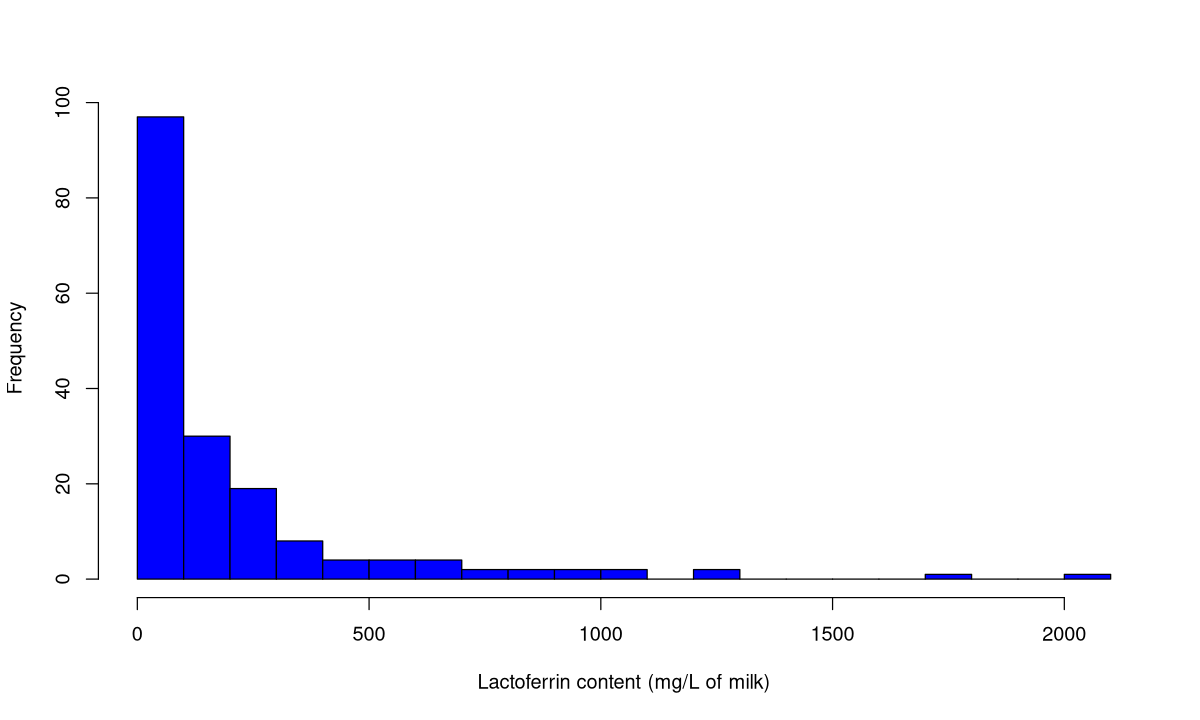

In [19]:
par(mfrow = c(1, 1))   # un graphique sur la page
hist(y$lactoferrin, breaks = 20, col = "blue",
     xlab = "Lactoferrin content (mg/L of milk)", main = NULL)

La distribution est très **asymétrique** (queue à droite) : la majorité des laits ont moins de 250 mg/L, quelques-uns dépassent 1000 mg/L.

### Formes de distribution
| Forme | Ordre des paramètres de position |
|---|---|
| **Symétrique** | mode = médiane = moyenne |
| **Asymétrique à droite** (queue vers les grandes valeurs) | mode < médiane < moyenne |
| **Asymétrique à gauche** (queue vers les petites valeurs) | moyenne < médiane < mode |

La moyenne est « tirée » vers la queue de la distribution (non robuste), la médiane un peu moins, le mode pas du tout.

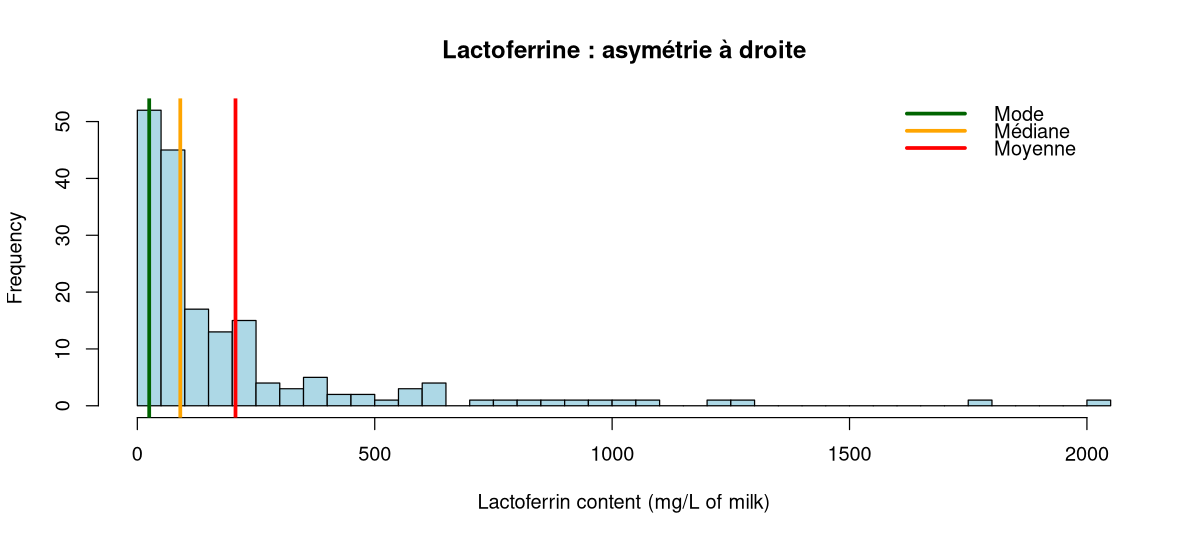

In [20]:
options(repr.plot.width = 10, repr.plot.height = 4.5)
h <- hist(x_lf, breaks = 30, col = "lightblue", main = "Lactoferrine : asymétrie à droite",
          xlab = "Lactoferrin content (mg/L of milk)")
abline(v = h$mids[which.max(h$counts)], col = "darkgreen", lwd = 3)   # mode (classe modale)
abline(v = median(x_lf), col = "orange", lwd = 3)                     # médiane
abline(v = mean(x_lf), col = "red", lwd = 3)                          # moyenne
legend("topright", c("Mode", "Médiane", "Moyenne"), col = c("darkgreen", "orange", "red"), lwd = 3, bty = "n", y.intersp = 1.3)

### Boxplot (boîte à moustaches)
Construction (Fig. 3 du syllabus) :
- la **boîte** va de $q_1$ à $q_3$ (longueur = IQR) ; le trait central = **médiane** ;
- les **moustaches** relient la boîte au minimum et au maximum, **sans dépasser 1.5 × IQR** ;
- toute observation $< q_1 - 1.5(q_3-q_1)$ ou $> q_3 + 1.5(q_3-q_1)$ est représentée par un point (astérisque) : **valeur exceptionnelle**.

Le boxplot renseigne sur l'**ordre de grandeur** (médiane), la **dispersion** (IQR, étendue), la **symétrie** (position de la médiane dans la boîte, longueurs des moustaches) et les **valeurs exceptionnelles**.

> **Fonction R** : `boxplot(x, horizontal = FALSE, col, main, ylab, range = 1.5)` ; `boxplot.stats(x)$stats` renvoie (moustache basse, q1, médiane, q3, moustache haute) et `$out` les valeurs exceptionnelles.

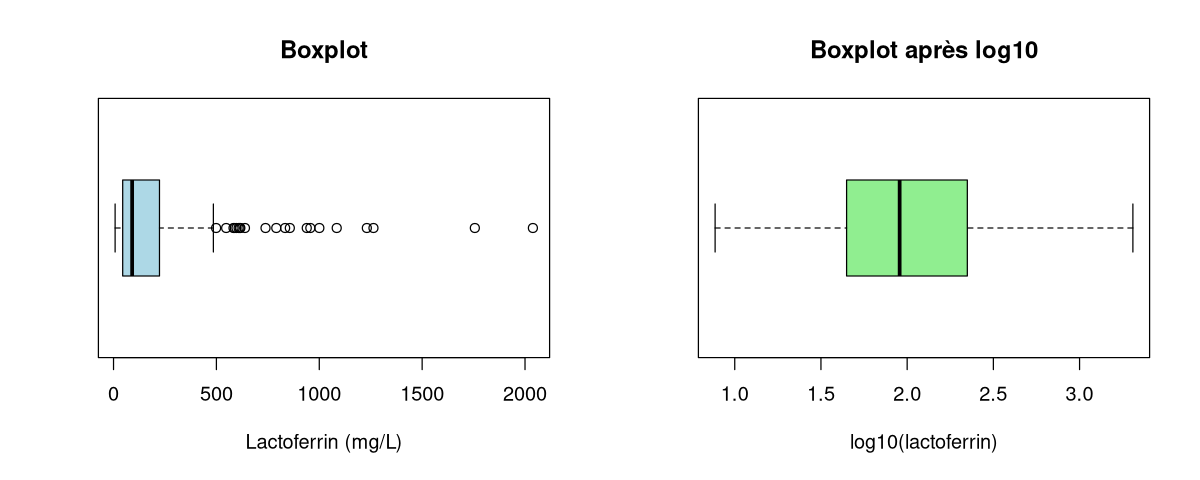

In [21]:
options(repr.plot.width = 10, repr.plot.height = 4)
par(mfrow = c(1, 2))
boxplot(x_lf, horizontal = TRUE, col = "lightblue", xlab = "Lactoferrin (mg/L)", main = "Boxplot")
boxplot(log10(x_lf), horizontal = TRUE, col = "lightgreen", xlab = "log10(lactoferrin)", main = "Boxplot après log10")
par(mfrow = c(1, 1))

In [22]:
bs <- boxplot.stats(x_lf)
bs$stats                 # moustache basse, q1, médiane, q3, moustache haute
length(bs$out)           # nombre de valeurs exceptionnelles
# Vérification de la règle 1.5 IQR « à la main » (boxplot utilise les charnières de Tukey ≈ quartiles)
q <- quantile(x_lf, c(0.25, 0.75))
q[2] + 1.5 * diff(q)     # borne haute
sum(x_lf > q[2] + 1.5 * diff(q))

[1]   7.69375  44.54000  90.46833 223.36000 485.26700

[1] 21

75% 
489.8579

[1] 21

### Exercice 1.5 : lire un boxplot
Trace le boxplot des points spectraux 713 et 649 (colonnes 714 et 650) côte à côte avec `boxplot(lactoferrin[, c(714, 650)])`. Lequel semble symétrique ? Lequel a des valeurs exceptionnelles ?

In [23]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
boxplot(lactoferrin[, c(714, 650)], names = c("pt 713", "pt 649"), col = "grey")
boxplot.stats(lactoferrin[, 714])$out
boxplot.stats(lactoferrin[, 650])$out
```

Observe la position de la médiane dans la boîte et la longueur des moustaches pour juger la symétrie ; les points isolés au-delà des moustaches sont les valeurs exceptionnelles (> 1.5 IQR).

</details>

## 1.7 La loi normale et la règle des 3σ

Si la variable suit une **loi normale** $\mathcal{N}(\mu, \sigma)$ :
- ≈ **68.2 %** des valeurs sont dans $\mu \pm 1\sigma$ (34.1 % de chaque côté) ;
- ≈ **95.4 %** dans $\mu \pm 2\sigma$ ;
- ≈ **99.6 %** (plus précisément 99.73 %) dans $\mu \pm 3\sigma$ (le cours arrondit à 99.6 %).

Conséquence : une valeur à **plus de 3 écarts-types de la moyenne** est **rare** et peut être considérée comme **outlier** (si la distribution est normale !).

In [24]:
# Proportions théoriques
pnorm(1) - pnorm(-1); pnorm(2) - pnorm(-2); pnorm(3) - pnorm(-3)

# Règle des 3σ sur la lactoferrine brute
z <- (x_lf - mean(x_lf)) / sd(x_lf)
which(abs(z) > 3)          # échantillons à plus de 3 écarts-types
x_lf[abs(z) > 3]

[1] 0.6826895

[1] 0.9544997

[1] 0.9973002

[1]  81 113 119 120

[1] 1263.383 1756.133 1231.200 2038.267

> **Attention** : la règle des 3σ suppose la **normalité**. Sur la lactoferrine brute, très asymétrique, elle signale des valeurs qui sont peut-être simplement la queue naturelle de la distribution (mammites). Il vaut mieux l'appliquer **après transformation** (log10, section 1.14).

### Exercice 1.6
Applique la règle des 3σ à `log10(lactoferrin)`. Combien d'échantillons sont signalés ?

In [25]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
lz <- log10(x_lf)
zl <- (lz - mean(lz)) / sd(lz)
sum(abs(zl) > 3)    # 0 : plus aucune valeur « anormale »
range(zl)
```

Après transformation, la distribution est proche de la normale et **aucune** valeur ne dépasse ±3σ : les « outliers » de l'échelle brute étaient la conséquence de l'asymétrie, pas des erreurs.

</details>

## 1.8 Variables qualitatives et tableau de contingence

Pour une variable qualitative (ou discrétisée) prenant $p$ valeurs différentes $x_i$ :
- **effectif** (fréquence absolue) $n_i$ : nombre d'occurrences de $x_i$, avec $n = \sum_{i=1}^{p} n_i$ ;
- **fréquence relative** $n'_i = \frac{n_i}{n}$ ;
- **effectif cumulé** $N(x_i)$ : nombre d'observations ≤ $x_i$ ; **fréquence relative cumulée** $N'(x_i) = \frac{N(x_i)}{n}$.

> **Fonctions R** : `table(x)` (effectifs), `prop.table(table(x))` (fréquences relatives), `cumsum()` (cumul), `cut(x, breaks, labels)` (discrétiser une variable quantitative en classes), `table(a, b)` (tableau croisé), `addmargins()` (totaux).

On discrétise la lactoferrine selon les repères de la littérature (voir 1.10) : < 100, 100–350, > 350 mg/L.

In [26]:
classe <- cut(x_lf, breaks = c(0, 100, 350, Inf), labels = c("<100", "100-350", ">350"))
ni <- table(classe)              # effectifs
ni
prop.table(ni)                   # fréquences relatives n'_i
cumsum(ni)                       # effectifs cumulés N(x_i) (la variable est ordonnée)
cumsum(prop.table(ni))           # fréquences relatives cumulées N'(x_i)

classe
   <100 100-350    >350 
     97      52      29 

classe
     <100   100-350      >350 
0.5449438 0.2921348 0.1629213 

<100 100-350    >350 
     97     149     178

<100   100-350      >350 
0.5449438 0.8370787 1.0000000

### Tableau de contingence
L'analyse **bivariée** aide aussi à détecter des comportements anormaux entre variables. Le **tableau de contingence** (*cross-tabulation*) compte les observations pour chaque combinaison de modalités ; les variables quantitatives doivent être **discrétisées** au préalable. Exemple du syllabus (Table 1) :

| | Primipares | Multipares |
|---|---|---|
| Jours en lait ≤ 100 | 12 354 | 13 800 |
| 100 < jours en lait ≤ 305 | 14 562 | 16 182 |
| Jours en lait > 305 | 10 963 | 15 022 |

In [27]:
tab1 <- matrix(c(12354, 14562, 10963, 13800, 16182, 15022), ncol = 2,
               dimnames = list(DIM = c("<=100", "100-305", ">305"),
                               Parite = c("Primipares", "Multipares")))
addmargins(tab1)                    # avec totaux
round(prop.table(tab1, 2) * 100, 1) # % en colonne : répartition des stades par parité

,Primipares,Multipares,Sum
<=100,12354,13800,26154
100-305,14562,16182,30744
>305,10963,15022,25985
Sum,37879,45004,82883


,Primipares,Multipares
<=100,32.6,30.7
100-305,38.4,36.0
>305,28.9,33.4


In [28]:
# Tableau croisé à partir de deux variables du jeu de données :
# classe de lactoferrine × absorbance au point 713 discrétisée en terciles
abs713 <- cut(lactoferrin[, 714], breaks = quantile(lactoferrin[, 714], c(0, 1/3, 2/3, 1)),
              labels = c("faible", "moyenne", "forte"), include.lowest = TRUE)
ct <- table(classe, abs713)
addmargins(ct)

,faible,moyenne,forte,Sum
<100,41,40,16,97
100-350,17,19,16,52
>350,2,0,27,29
Sum,60,59,59,178


On voit que les laits riches en lactoferrine (> 350) ont surtout une absorbance « forte » au point 713 : c'est le lien qu'exploitera la régression.

### Exercice 1.7
Calcule les **pourcentages en ligne** du tableau `ct` (chaque ligne somme à 100 %). Quelle proportion des laits à plus de 350 mg/L a une absorbance « forte » ?

In [29]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
round(prop.table(ct, margin = 1) * 100, 1)   # margin = 1 → lignes ; margin = 2 → colonnes
```

`prop.table(ct, 1)` divise chaque cellule par le total de sa ligne. On lit dans la ligne « >350 » la proportion d'absorbances fortes.

</details>

## 1.9 Valeurs anormales et manquantes

> **Définition : outlier (valeur aberrante)**
> Valeur **erronée** causée par un mauvais encodage, une erreur de mesure ou de calcul, etc.
> - Une **valeur extrême n'est pas toujours un outlier** : si le protocole a peu échantillonné les valeurs hautes/basses, elles existent quand même.
> - Un **outlier n'est pas toujours une valeur extrême** (ex. une valeur plausible mais encodée dans la mauvaise ligne).

Détection :
- les **statistiques descriptives univariées** identifient facilement la plupart des outliers ;
- pour des outliers non extrêmes ou un grand nombre de variables : une **ACP couplée à une mesure de distance** (cf. AM1) est très utile ;
- même si ce ne sont pas des outliers, il est de bonne pratique de **rechercher les valeurs extrêmes**, car elles influencent fortement les modèles (on le verra avec la distance de Cook).

**Actions possibles** (pour une valeur anormale **ou manquante**) :
1. **Supprimer la variable** si le pourcentage d'outliers/manquants est trop élevé (ex. **15 à 20 %**) : la variable est peu fiable ; la remplacer éventuellement par une variable proche ;
2. **Supprimer la ligne** (l'enregistrement) : réduit la quantité de données disponible ;
3. **Remplacer la valeur** (imputation **simple**) : valeur la plus observée, moyenne, médiane, estimation par arbre de décision…
4. **Imputation multiple** (Donald Rubin) : remplacer par **plusieurs valeurs plausibles**, analyser chaque jeu complété et **combiner** les résultats.

Le choix dépend de l'importance de la variable, du nombre d'observations perdues et de la précision de la méthode d'imputation. Si on impute, il faut vérifier que les **relations** entre variables explicatives et variable à expliquer ne sont **pas cassées** ou fortement modifiées.

In [30]:
# Le fichier lactoferrine ne contient aucune valeur manquante :
any(is.na(lactoferrin))
sum(is.na(lactoferrin))

# Démonstration sur une copie dans laquelle on introduit des NA
set.seed(1)
lf_na <- lactoferrin[, c(1, 714, 1062)]       # ID, point 713, lactoferrine
lf_na[sample(1:178, 12), 3] <- NA              # 12 lactoferrines manquantes
lf_na[sample(1:178, 5), 2]  <- NA              # 5 absorbances manquantes
colSums(is.na(lf_na))                          # nombre de NA par colonne
round(colMeans(is.na(lf_na)) * 100, 1)         # % de NA par colonne (seuil 15-20 % ?)

[1] FALSE

[1] 0

V1  V714 V1062 
    0     5    12

V1  V714 V1062 
  0.0   2.8   6.7

> **Fonctions R pour les NA**
> | Fonction | Rôle |
> |---|---|
> | `is.na(x)` | `TRUE` là où la valeur manque |
> | `colSums(is.na(df))` | nombre de NA par colonne |
> | `complete.cases(df)` | `TRUE` pour les lignes **sans** aucun NA |
> | `na.omit(df)` | supprime les lignes contenant un NA |
> | `mean(x, na.rm = TRUE)` | ignore les NA dans un calcul (sinon le résultat est `NA`) |

In [31]:
mean(lf_na$V1062)                    # NA : un seul NA « contamine » le calcul
mean(lf_na$V1062, na.rm = TRUE)

# Action 2 : supprimer les lignes incomplètes
sum(complete.cases(lf_na))           # lignes complètes
dim(na.omit(lf_na))

# Action 3 : imputation simple par la médiane (robuste, adaptée à une variable asymétrique)
lf_imp <- lf_na
med <- median(lf_imp$V1062, na.rm = TRUE)
lf_imp$V1062[is.na(lf_imp$V1062)] <- med
sum(is.na(lf_imp$V1062))

# Les relations sont-elles préservées ? corrélation absorbance-lactoferrine avant/après
cor(lactoferrin[, 714], lactoferrin[, 1062])
cor(lf_imp$V714, lf_imp$V1062, use = "complete.obs")

[1] NA

[1] 213.6864

[1] 161

[1] 161   3

[1] 0

[1] 0.4628393

[1] 0.4623166

> **Complément** : l'imputation par une constante (moyenne/médiane) **réduit la variance** de la variable et **affaiblit les corrélations** (les valeurs imputées ne suivent pas la relation avec x). C'est pourquoi le cours insiste sur la vérification des relations après imputation, et pourquoi l'imputation multiple (Rubin), qui propage l'incertitude, est préférable quand les NA sont nombreux.

### Exercice 1.8 : imputation par la moyenne
Sur `lf_na`, impute les absorbances manquantes de `V714` par la **moyenne** de la colonne, puis compare l'écart-type de `V714` avant (sur les valeurs observées) et après imputation.

In [32]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
v <- lf_na$V714
sd(v, na.rm = TRUE)                      # avant (valeurs observées)
v[is.na(v)] <- mean(v, na.rm = TRUE)     # imputation simple par la moyenne
sd(v)                                    # après : légèrement plus petit
```

Les valeurs imputées sont toutes au centre de la distribution : la dispersion diminue artificiellement.

</details>

## 1.10 Validation des données : comparaison avec la littérature

La dernière étape du *data cleaning* consiste à vérifier que les valeurs sont **attendues** :

| Source | Teneur en lactoferrine du lait |
|---|---|
| FIL-IDF (2008) | ≈ 100 mg/L |
| Sérieys (1997) : variation avec le stade de lactation | 30 mg/L au 30ᵉ jour ; 60 mg/L au 150ᵉ jour ; 150 mg/L au 270ᵉ jour |
| Senft et al. (1976) | de 20 à 350 mg/L |
| Gaunt et al. (1980) : **laits de vaches à mammite** | de 20 à **1890** mg/L |

Nos données : Min 7.69 ; Q1 44.85 ; Médiane 90.47 ; Moyenne 206.7 ; Q3 222.9 ; **Max 2038** mg/L. → **Outliers ?**

In [33]:
summary(x_lf)
sum(x_lf > 350)                      # au-dessus de la gamme « normale » de Senft et al.
sum(x_lf > 1890)                     # au-dessus du maximum rapporté pour les mammites
x_lf[x_lf > 1890]
sum(x_lf < 20)                       # sous le minimum rapporté

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
   7.694   44.850   90.468  206.746  222.853 2038.267 

[1] 29

[1] 1

[1] 2038.267

[1] 9

**Interprétation** : la médiane (90 mg/L) est cohérente avec la valeur de référence de 100 mg/L. Les valeurs élevées (> 350 mg/L) sont plausibles pour des **laits de mammite** ; seule la valeur de 2038 mg/L dépasse légèrement le maximum de la littérature (1890 mg/L) : elle mérite d'être vérifiée (erreur de dilution ELISA ?) mais ce n'est pas forcément une erreur. Quelques valeurs < 20 mg/L sont aussi un peu basses. On **garde** ces données pour l'instant, en surveillant leur influence dans les régressions.

### Graphique de validation : histogramme en pourcentage
Les slides montrent l'histogramme en **pourcentage** d'échantillons :

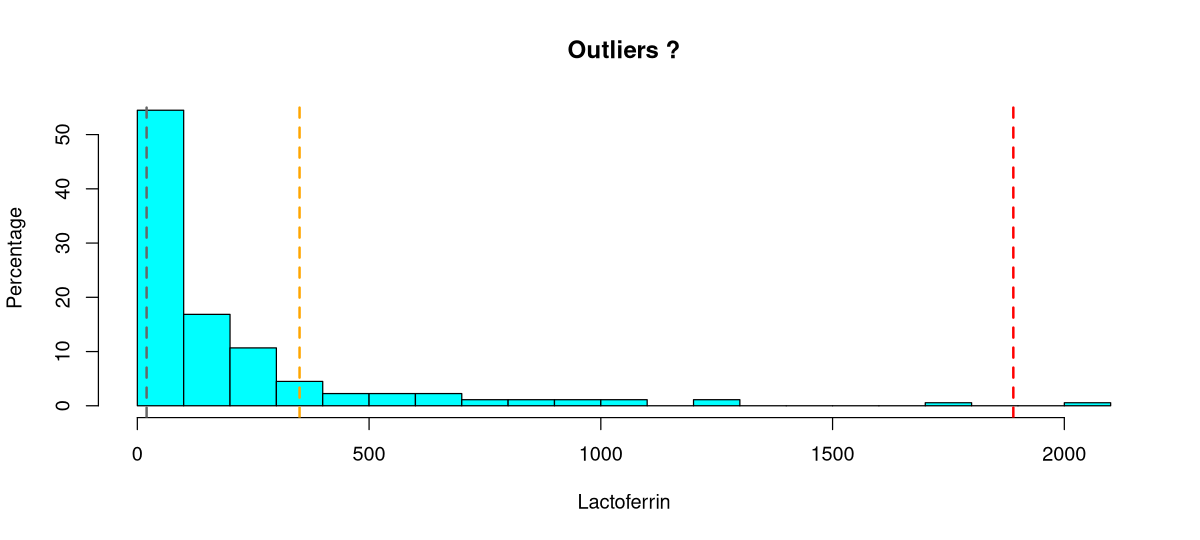

In [34]:
options(repr.plot.width = 10, repr.plot.height = 4.5)
h <- hist(x_lf, breaks = 20, plot = FALSE)
h$counts <- h$counts / sum(h$counts) * 100   # effectifs → pourcentages
plot(h, col = "cyan", ylab = "Percentage", xlab = "Lactoferrin", main = "Outliers ?")
abline(v = c(20, 350, 1890), col = c("grey40", "orange", "red"), lty = 2, lwd = 2)

## 1.11 Données spectrales : beaucoup de variables

Avec 1060 variables explicatives, on ne peut pas examiner chaque variable une à une : on travaille **graphiquement**, en calculant les statistiques **par point spectral** (par colonne).

### Spectre moyen (« Expected ? »)
Le spectre moyen doit avoir l'allure attendue d'un spectre MIR de lait (comparaison à la littérature, ex. Grelet et al., 2015).

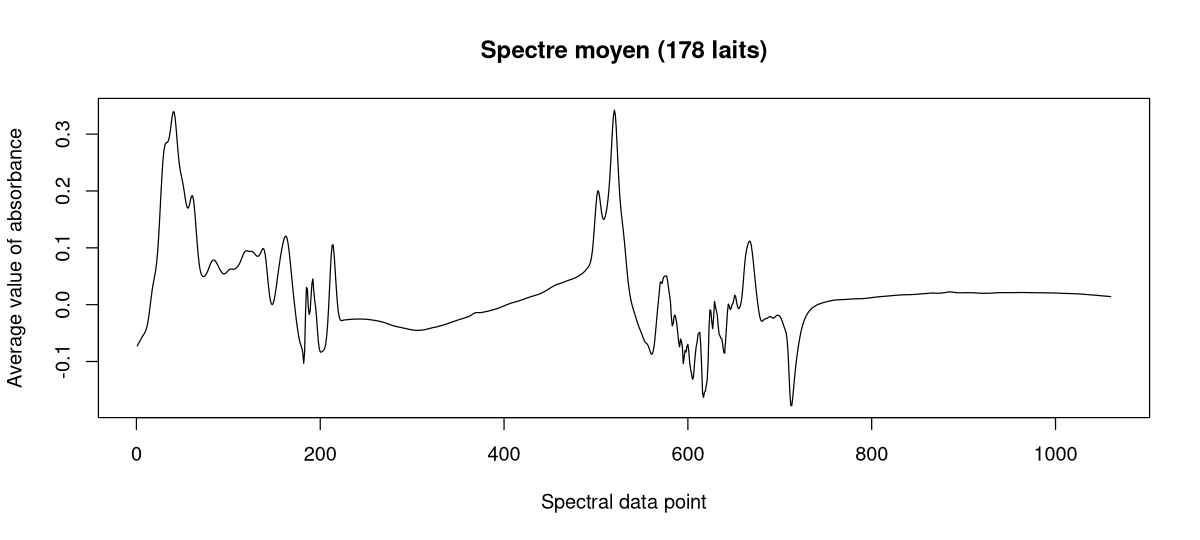

In [35]:
spectre <- lactoferrin[, 2:1061]          # 1060 points spectraux
moyenne <- colMeans(spectre)              # équivalent à apply(spectre, 2, mean) ; slide : mean[2:1061]
options(repr.plot.width = 10, repr.plot.height = 4.5)
plot(moyenne, type = "l", xlab = "Spectral data point", ylab = "Average value of absorbance",
     main = "Spectre moyen (178 laits)")

### Coefficient de variation par point spectral (« Some noisy regions »)
Le CV de chaque point spectral révèle les **régions bruitées** : là où l'absorbance moyenne est proche de 0, $cv = s/\bar{x}$ explose (division par ~0) et ces régions sont peu informatives (cf. *origin* : « some regions are uninformative »).

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
    3.627    11.706    27.152   249.135    46.359 69904.393 

V649 
 648

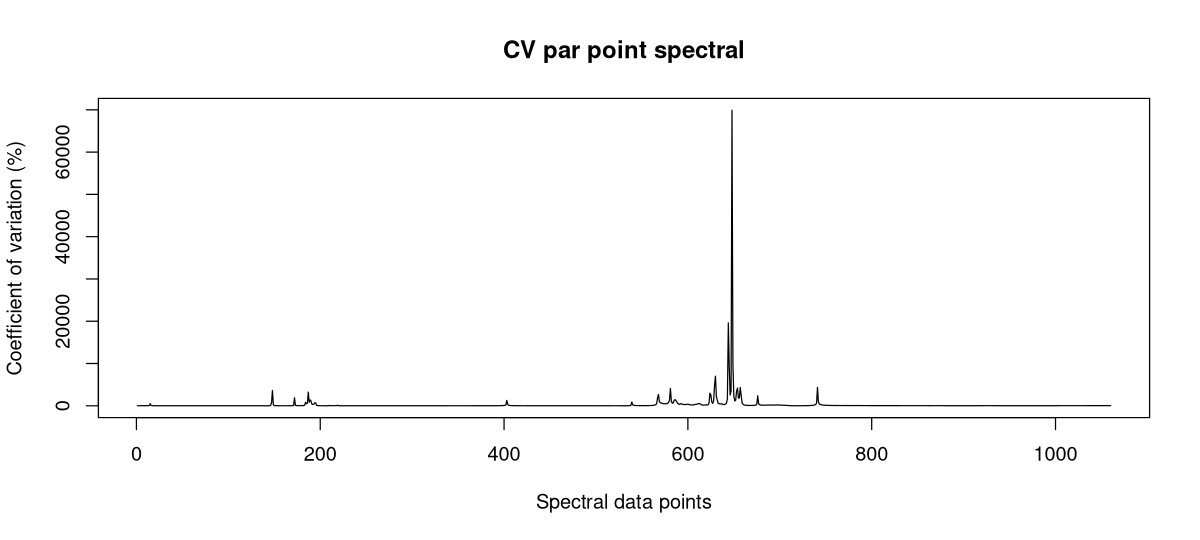

In [36]:
CVspec <- apply(spectre, 2, sd) / abs(colMeans(spectre)) * 100   # CV en %, valeur absolue de la moyenne
summary(CVspec)
plot(CVspec, type = "l", xlab = "Spectral data points", ylab = "Coefficient of variation (%)",
     main = "CV par point spectral")
which.max(CVspec)

> **Complément** : le pic de CV autour du point 648 (≈ 70 000 %, comme sur la slide) correspond à une absorbance moyenne quasiment nulle. Un CV élevé n'est pas forcément de l'information : ici, c'est surtout du **bruit** rapporté à une moyenne minuscule. Les régions très bruitées (absorption de l'eau dans le spectre MIR) sont souvent exclues dans les applications réelles.

### Exercice 1.9 : régions bruitées
1. Combien de points spectraux ont un CV supérieur à 100 % ?
2. Trace le spectre moyen et ajoute, en rouge, des points sur les positions dont le CV dépasse 100 % (`points(which(...), moyenne[which(...)], col = "red")`).

In [37]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
bruit <- which(CVspec > 100)
length(bruit)
plot(moyenne, type = "l", xlab = "Spectral data point", ylab = "Average value of absorbance")
points(bruit, moyenne[bruit], col = "red", pch = 20, cex = 0.6)
```

Les points à CV élevé sont ceux où le spectre moyen croise ou frôle zéro.

</details>

## 1.12 Colinéarité

> **Définition : colinéarité**
> Il y a colinéarité quand des variables sont **fortement corrélées** entre elles. Toutes les méthodes de ML ne savent pas la gérer (la régression linéaire classique, notamment : voir notebooks 03 et 06). Il peut donc être recommandé de **supprimer une ou plusieurs variables** trop corrélées à d'autres.

Pour les spectres, la colinéarité est **structurelle** : deux points spectraux adjacents mesurent quasiment la même fréquence, donc les vibrations des mêmes molécules.

> **Fonction R** : `cor(x, y = NULL, method = "pearson")`
> - `cor(df)` : matrice de corrélation entre toutes les colonnes (p × p) ;
> - `cor(X, y)` : corrélations de chaque colonne de X avec y ;
> - `method = "spearman"` : corrélation de rang (relations monotones non linéaires).
>
> `image(M)` : carte de chaleur rapide d'une matrice ; `corrplot::corrplot(M, method = "color")` : visualisation soignée.

[1] 1061 1061

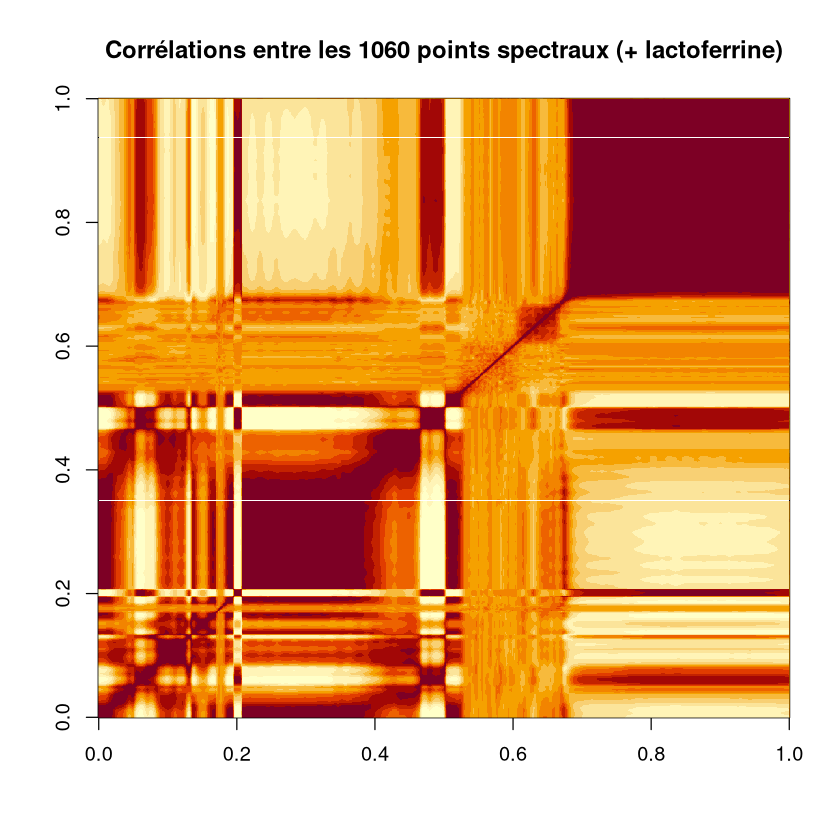

In [38]:
correlation <- cor(lactoferrin[, 2:1062])   # matrice 1061 × 1061 (spectre + lactoferrine), comme dans training.R
dim(correlation)
options(repr.plot.width = 7, repr.plot.height = 7)
image(correlation, main = "Corrélations entre les 1060 points spectraux (+ lactoferrine)")

La diagonale « épaisse » montre que chaque point spectral est très corrélé à ses voisins. Zoom sur 10 points adjacents (rappel : la colonne `V706` contient le point spectral 705, à cause de l'identifiant en colonne 1) :

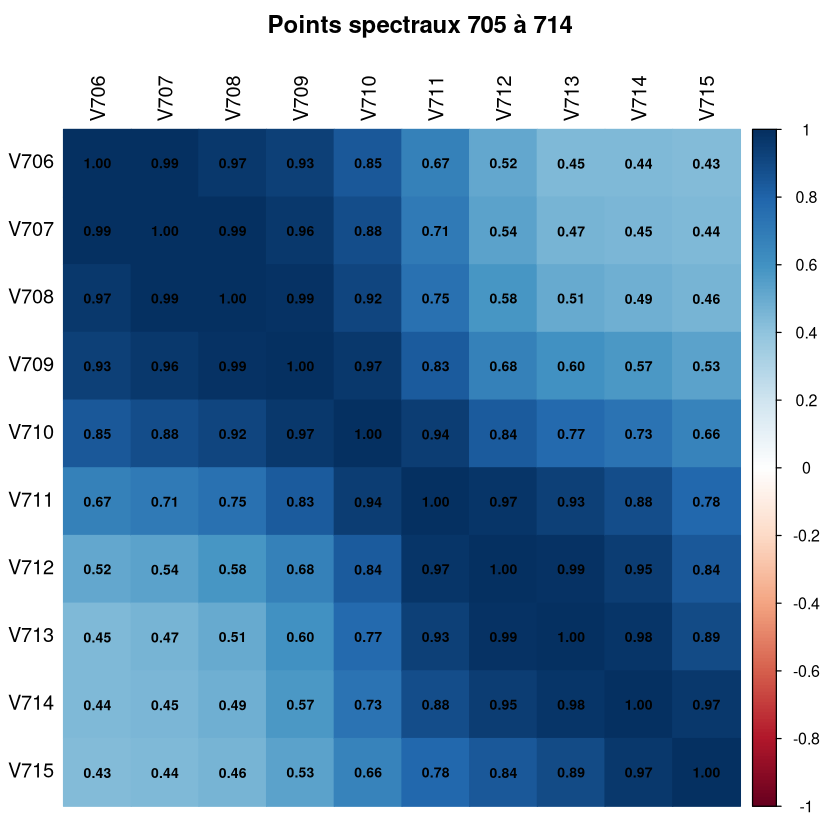

In [39]:
options(repr.plot.width = 7, repr.plot.height = 7)
corrplot(cor(lactoferrin[, 706:715]), method = "color", addCoef.col = "black", number.cex = 0.7,
         tl.col = "black", title = "Points spectraux 705 à 714", mar = c(0, 0, 2, 0))

> **Complément** : `corrplot(correlation)` sur la matrice entière (comme tenté dans `training.R`) dessine plus d'un million de cellules : c'est très lent et illisible. Pour beaucoup de variables, utilise `image()` ou restreins-toi à une sous-matrice.

### Exercice 1.10
Calcule la corrélation entre le point spectral 713 (colonne 714) et (a) son voisin 712 (colonne 713), (b) le point 300 (colonne 301). Commente.

In [40]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
cor(lactoferrin[, 714], lactoferrin[, 713])   # ≈ 0.98 : quasi la même information
cor(lactoferrin[, 714], lactoferrin[, 301])   # beaucoup plus faible
```

Deux points **adjacents** sont presque parfaitement corrélés (colinéarité), deux points **éloignés** beaucoup moins.

</details>

## 1.13 Mise à l'échelle (*scaling*)

Les variables peuvent avoir des **échelles différentes** (moyennes et variances différentes). Dans la grande majorité des cas, un **redimensionnement** est souhaitable (indispensable pour les régressions pénalisées et la descente de gradient). Deux méthodes principales :

**1. Par l'étendue (*range*, *min-max*)**
$$x_i' = \frac{x_i - x_{min}}{x_{max} - x_{min}} \qquad 0 \le x_i' \le 1$$

**2. Par l'écart-type : *autoscaling*** (centrage-réduction, standardisation)
$$x_i' = \frac{x_i - \bar{x}}{\sigma_x} \qquad \Rightarrow \bar{x}' = 0,\; \sigma_{x'} = 1$$

> **Fonction R** : `scale(x, center = TRUE, scale = TRUE)`
> - appliquée colonne par colonne à une matrice/data.frame ;
> - `center = TRUE` soustrait la moyenne, `scale = TRUE` divise par l'écart-type (en $n-1$) ;
> - on peut passer des vecteurs : `scale(x, center = mins, scale = maxs - mins)` réalise le min-max ;
> - renvoie une **matrice** avec les attributs `"scaled:center"` et `"scaled:scale"` (utiles pour appliquer la **même** transformation à de nouvelles données).

In [41]:
# Autoscaling de tout le spectre
spectre_auto <- scale(spectre)
mspectra <- colMeans(spectre_auto)
range(mspectra)                         # ≈ 1e-15 : zéro numérique
range(apply(spectre_auto, 2, sd))       # tous les écarts-types valent 1

# Min-max
mins <- apply(spectre, 2, min); maxs <- apply(spectre, 2, max)
spectre_mm <- scale(spectre, center = mins, scale = maxs - mins)
mminmaxx <- colMeans(spectre_mm)
range(spectre_mm)                       # entre 0 et 1

[1] -2.130387e-15  2.517123e-15

[1] 1 1

[1] 0 1

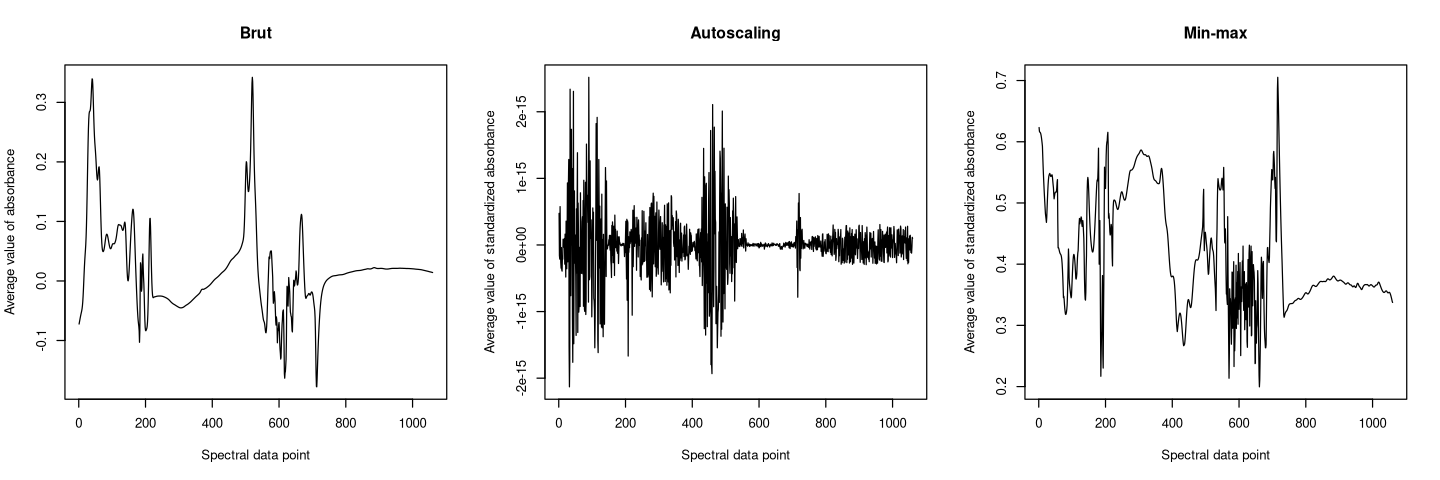

In [42]:
options(repr.plot.width = 12, repr.plot.height = 4)
par(mfrow = c(1, 3))
plot(moyenne, type = "l", xlab = "Spectral data point", ylab = "Average value of absorbance", main = "Brut")
plot(mspectra, type = "l", xlab = "Spectral data point", ylab = "Average value of standardized absorbance",
     main = "Autoscaling")
plot(mminmaxx, type = "l", xlab = "Spectral data point", ylab = "Average value of standardized absorbance",
     main = "Min-max")
par(mfrow = c(1, 1))

**Lecture (comme sur les slides)** : après *autoscaling*, la moyenne de chaque point vaut 0 : le graphe n'est plus que du bruit numérique de l'ordre de 10⁻¹⁵ (l'axe des ordonnées le montre). Après *min-max*, les moyennes sont entre 0.2 et 0.7 et l'allure du spectre change : chaque point est ramené sur [0, 1], indépendamment de son absorbance d'origine.

> **Complément** : le syllabus mentionne aussi, pour accélérer la descente de gradient (notebook 05), la division par le **maximum** (valeurs ≈ entre −1 et 1) et le centrage suivi d'une division par l'écart-type, le maximum ou l'étendue.

### Exercice 1.11 : vérifier le min-max à la main
Applique la formule min-max **à la main** à la lactoferrine et vérifie que tu obtiens le même résultat que `scale(x_lf, center = min(x_lf), scale = diff(range(x_lf)))`.

In [43]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
mm_main <- (x_lf - min(x_lf)) / (max(x_lf) - min(x_lf))
mm_scale <- scale(x_lf, center = min(x_lf), scale = diff(range(x_lf)))
all.equal(mm_main, as.numeric(mm_scale))   # TRUE
range(mm_main)                             # 0 et 1
```

`as.numeric()` retire les attributs de la matrice renvoyée par `scale()` pour comparer deux vecteurs.

</details>

## 1.14 Transformations vers la normalité

La distribution de la lactoferrine est **asymétrique**. Beaucoup de méthodes (régression linéaire et ses tests) supposent la normalité… des **résidus**. Une transformation de y peut aider : **log10** ou **racine carrée** (adaptées aux distributions asymétriques à droite de variables positives).

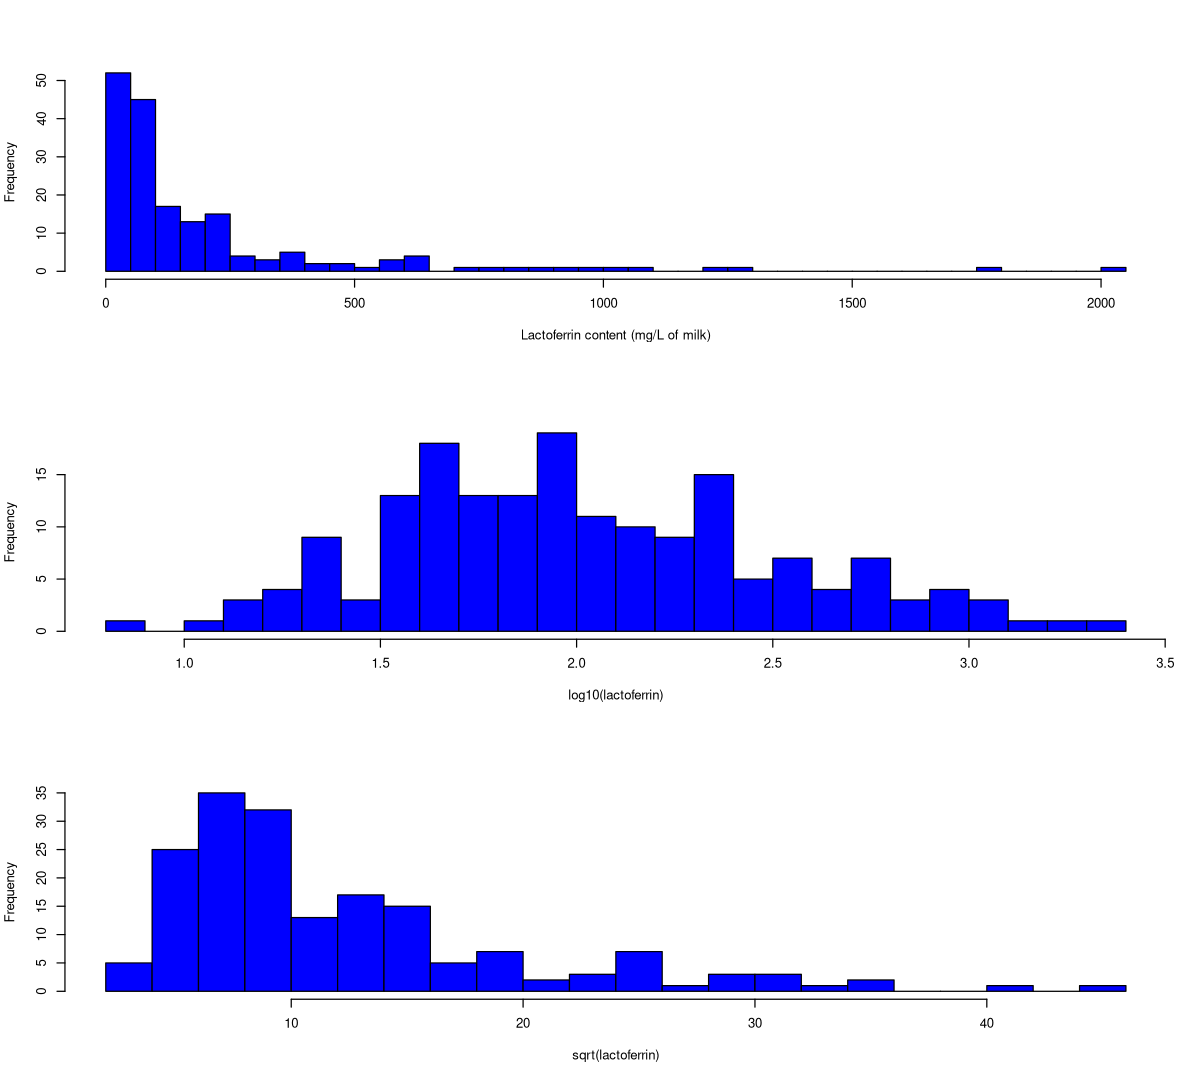

In [44]:
options(repr.plot.width = 10, repr.plot.height = 9)
par(mfrow = c(3, 1))   # 3 lignes pour dessiner les graphiques dans une colonne
hist(y$lactoferrin, breaks = 30, col = "blue", main = NULL, xlab = "Lactoferrin content (mg/L of milk)")
hist(log10(y$lactoferrin), breaks = 30, col = "blue", main = NULL, xlab = "log10(lactoferrin)")
hist(sqrt(y$lactoferrin), breaks = 30, col = "blue", main = NULL, xlab = "sqrt(lactoferrin)")
par(mfrow = c(1, 1))

In [45]:
summary(log10(x_lf))     # Min 0.8861, Q1 1.652, Médiane 1.956, Moyenne 2.020, Q3 2.348, Max 3.309 (slides)
# descr() aime recevoir un objet existant (pas un data.frame construit dans l'appel)
transfo <- data.frame(brut = x_lf, log10 = log10(x_lf), sqrt = sqrt(x_lf))
descr(transfo, stats = c("mean", "med", "sd", "skewness", "kurtosis"), transpose = TRUE, order = "preserve")

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.8861  1.6517  1.9565  2.0200  2.3480  3.3093 

,Mean,Median,Std.Dev,Skewness,Kurtosis
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
brut,206.745862,90.468333,301.6944572,3.1035998,11.7637127
log10,2.020004,1.956471,0.4921172,0.3586346,-0.4026046
sqrt,12.107040,9.511342,7.7785193,1.6493377,2.8071867


**Conclusion (résolution)** : la distribution **la plus symétrique** est obtenue avec la **transformation logarithmique** (moyenne ≈ médiane, skewness ≈ 0). Son intérêt sera **confirmé lors de l'analyse des résidus** (notebook 02) : ce qui compte en régression, c'est la normalité des résidus, pas celle de y en elle-même.

> **Attention** : `log10()` exige des valeurs **strictement positives** ; avec des zéros, on utilise `log10(x + 1)` (ou une petite constante). La racine carrée accepte les zéros.

> **Complément** : après une modélisation sur `log10(y)`, les prédictions sont en échelle log ; on revient en mg/L avec `10^prediction`.

### Exercice 1.12 : quelle transformation ?
Pour la lactoferrine, compare les p-valeurs du test de normalité de Shapiro-Wilk (`shapiro.test()`, H₀ : distribution normale) sur y brut, log10(y) et sqrt(y). Laquelle « passe » le test au seuil de 5 % ?

In [46]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
shapiro.test(x_lf)$p.value          # très petite : normalité rejetée
shapiro.test(log10(x_lf))$p.value   # la plus grande
shapiro.test(sqrt(x_lf))$p.value    # encore très petite
```

Seule la transformation log10 rend la distribution compatible (ou presque) avec la normalité. Rappel : en régression, le test se fera sur les **résidus** (`shapiro.test(resid(modele))`).

</details>

### Questions de compréhension

1. Une distribution a une moyenne de 50 et une médiane de 30. Est-elle asymétrique à droite ou à gauche ?
2. Pourquoi l'IQR est-il qualifié de « robuste » ?
3. Vrai ou faux : toute valeur à plus de 3σ de la moyenne est un outlier qu'il faut supprimer.
4. Vrai ou faux : après *autoscaling*, toutes les variables ont la même variance.
5. Pourquoi ne faut-il jamais utiliser `V1` comme variable explicative ?
6. Que vaut le CV d'une variable dont la moyenne est proche de 0, et pourquoi est-ce trompeur ?

<details>
<summary><b>Voir les réponses</b></summary>

1. Moyenne > médiane → **asymétrique à droite** (queue vers les grandes valeurs ; mode < médiane < moyenne).
2. Il ne dépend que de $q_1$ et $q_3$, donc pas des 25 % d'observations les plus basses ni des 25 % les plus hautes : les valeurs extrêmes ne l'influencent presque pas.
3. **Faux** : la règle ne vaut que pour une distribution **normale** ; une valeur extrême peut être réelle (mammite). Avant de supprimer, on vérifie l'origine (encodage, mesure) et on compare à la littérature.
4. **Vrai** : variance = 1 (et moyenne = 0) pour toutes les variables.
5. C'est un **identifiant** (qualitatif nominal codé en entier) : il n'a aucun lien biologique avec y ; un lien éventuel serait un artefact de l'ordre d'enregistrement.
6. Il devient énorme (division par ~0) sans refléter une réelle variabilité informative : c'est ce qui crée les pics à ~70 000 % dans les régions bruitées du spectre.

</details>

## Récapitulatif

- **Types** : quantitatives (discrètes, continues) / qualitatives (binaires, nominales, ordinales) ; une qualitative codée en chiffres reste qualitative.
- **Knowing the data** : *origin* (méthode, répétabilité ±10 %, reproductibilité ±20 %, labos, techniciens), *distribution* (graphes + stats), *validation* (littérature : ~100 mg/L, 20-350 mg/L, jusqu'à 1890 mg/L en mammite).
- **Position** : moyenne (non robuste), médiane et quartiles (robustes), mode, min, max. **Dispersion** : variance (1/n syllabus, 1/(n−1) dans R), écart-type, CV (sans unité), étendue, IQR (robuste).
- **Formes** : symétrique (mode = médiane = moyenne) ; asymétrie à droite (mode < médiane < moyenne). Boxplot : boîte q1–q3, moustaches ≤ 1.5 IQR.
- **Loi normale** : 68.2 % / 95.4 % / 99.6-99.7 % dans ±1/2/3σ → règle des 3σ (seulement si normal).
- **Qualitatives** : effectifs, fréquences relatives, cumulées ; tableau de contingence (variables discrétisées).
- **Outliers/NA** : supprimer la variable (15-20 %), la ligne, imputer (simple ou multiple) en préservant les relations.
- **Spectres** : spectre moyen, CV par point (régions bruitées), **colinéarité** structurelle des points adjacents.
- **Scaling** : min-max [0, 1] ou autoscaling (moyenne 0, écart-type 1).
- **Transformation** : log10 rend la lactoferrine symétrique → à confirmer sur les résidus.

| Fonction | Rôle |
|---|---|
| `factor(..., ordered=)`, `class()`, `levels()` | types de variables |
| `mean`, `median`, `quantile(type=)`, `min`, `max` | position |
| `var`, `sd`, `IQR`, `range`, `diff` | dispersion |
| `summary`, `summarytools::descr(transpose=TRUE)` | statistiques descriptives |
| `hist(breaks, col, xlab, main)`, `boxplot`, `boxplot.stats` | graphiques univariés |
| `pnorm` | probabilités de la loi normale |
| `table`, `prop.table`, `cumsum`, `cut`, `addmargins` | qualitatives, contingence |
| `is.na`, `complete.cases`, `na.omit`, `na.rm = TRUE` | valeurs manquantes |
| `colMeans`, `apply(X, 2, f)` | statistiques par colonne (spectres) |
| `cor`, `image`, `corrplot` | colinéarité |
| `scale(center, scale)` | autoscaling, min-max |
| `log10`, `sqrt`, `shapiro.test` | transformations, normalité |

**Suite** : `02_Regression_lineaire_univariee` : on cherche le point spectral le plus lié à la lactoferrine et on construit la première équation de prédiction.